# NYC Residential Property Sales | Data Science Project

**Question:** How well can public property records predict NYC one- to three-family home sale prices, and where does prediction fail?

**Data:** NYC Department of Finance, [Citywide Rolling Calendar Sales](https://www.nyc.gov/site/finance/property/property-rolling-sales-data.page), Oct 2025–Sep 2026. Recorded sale prices, not asking prices. Analysis covers screened transactions, not every NYC sale.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

RESULTS_DIR = Path("results")

for folder in [
    "eda",
    "feature_analysis",
    "model_comparison",
    "evaluation"
]:
    (RESULTS_DIR / folder).mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

def save_chart(filename, category="eda"):
    """Save a chart as a high-resolution PNG and vector PDF."""
    output = RESULTS_DIR / category
    output.mkdir(parents=True, exist_ok=True)

    plt.savefig(
        output / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.savefig(
        output / f"{filename}.pdf",
        bbox_inches="tight"
    )

    plt.show()

print("Results directories created.")


Results directories created.


In [3]:
# Portable dataset location: place export.csv beside the notebook under Data/Raw/.
# Both Data/Raw/ and Data/raw/ are supported to accommodate existing folders.
from pathlib import Path

DATA_CANDIDATES = [
    Path("../Data/Raw/export.csv"),
    Path("Data/raw/export.csv"),
    Path("export.csv"),
]

DATA_PATH = next((p for p in DATA_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "NYC sales file not found. Place export.csv in Data/Raw/ "
        "relative to the Jupyter working directory (or beside the notebook). "
        f"Current working directory: {Path.cwd()}"
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset loaded from: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())


Dataset loaded from: C:\Users\kael7\OneDrive\Desktop\learning-projects\Houston-Housing\Data\Raw\export.csv
Rows: 82,576
Columns: 21


,BOROUGH,NEIGHBORHOOD,BUILDING CLASS CATEGORY,TAX CLASS AT PRESENT,BLOCK,LOT,EASE-MENT,BUILDING CLASS AT PRESENT,ADDRESS,APARTMENT NUMBER,ZIP CODE,RESIDENTIAL UNITS,COMMERCIAL UNITS,TOTAL UNITS,LAND SQUARE FEET,GROSS SQUARE FEET,YEAR BUILT,TAX CLASS AT TIME OF SALE,BUILDING CLASS AT TIME OF SALE,SALE PRICE,SALE DATE
0,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2B,372,9,NaN,C7,272 EAST 3 STREET,NaN,"10,009.00",8,1.00,9,"2,021","7,129","1,900.00",2,C7,$0,12/15/2025
1,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,376,41,NaN,C6,"745 EAST 6TH STREET, 1B",NaN,"10,009.00",28,0.00,28,"4,542","18,254","1,900.00",2,C4,"$540,000",12/17/2025
2,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2A,377,50,NaN,C2,"275 EAST 7TH STREET, 3",NaN,"10,009.00",5,0.00,5,"2,169","6,294","1,900.00",2,C2,"$1,250,000",05/27/2026
3,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,385,38,NaN,C6,"21-23 AVENUE C, 5B",NaN,"10,009.00",20,2.00,22,"3,315","17,160","1,900.00",2,C4,$0,11/11/2025
4,1,ALPHABET CITY,07 RENTALS - WALKUP APARTMENTS,2,385,50,NaN,C4,240 EAST 2ND STREET,NaN,"10,009.00",24,0.00,24,"2,623","11,322","1,910.00",2,C4,$0,05/29/2026


## 1. Data audit and cleaning

We started with **82,576** records. We kept one-, two- and three-family dwellings, excluded zero/nominal transfers (≤$1,000), and checked missing or invalid areas and dates. **18,599** sales remained; this screening may exclude some genuine low-price transactions.

In [4]:

print("=" * 50)
print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nCOLUMN NAMES")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
}).sort_values("Missing %", ascending=False)

display(missing_summary)

print("\nEXACT DUPLICATE ROWS")
print(df.duplicated().sum())

print("\nNUMERICAL SUMMARY")
display(df.describe().T)

print("\nCATEGORICAL SUMMARY")
display(df.describe(include=["object", "category"]).T)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82576 entries, 0 to 82575
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   BOROUGH                         82576 non-null  int64  
 1   NEIGHBORHOOD                    82576 non-null  object 
 2   BUILDING CLASS CATEGORY         82576 non-null  object 
 3   TAX CLASS AT PRESENT            82576 non-null  object 
 4   BLOCK                           82576 non-null  int64  
 5   LOT                             82576 non-null  object 
 6   EASE-MENT                       0 non-null      float64
 7   BUILDING CLASS AT PRESENT       82576 non-null  object 
 8   ADDRESS                         82575 non-null  object 
 9   APARTMENT NUMBER                20690 non-null  object 
 10  ZIP CODE                        82560 non-null  float64
 11  RESIDENTIAL UNITS               62554 non-null  object 
 12  COMMERCIAL U

,Missing Count,Missing %
EASE-MENT,82576,100.00
APARTMENT NUMBER,61886,74.94
GROSS SQUARE FEET,37716,45.67
LAND SQUARE FEET,37716,45.67
COMMERCIAL UNITS,34626,41.93
RESIDENTIAL UNITS,20022,24.25
TOTAL UNITS,16932,20.50
YEAR BUILT,5397,6.54
ZIP CODE,16,0.02
BOROUGH,0,0.00



EXACT DUPLICATE ROWS
0

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
BOROUGH,"82,576.00",2.94,1.30,1.00,2.00,3.00,4.00,5.00
BLOCK,"82,576.00","4,160.19","3,557.79",1.00,"1,259.00","3,225.50","6,156.00","16,350.00"
EASE-MENT,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZIP CODE,"82,560.00","10,847.37",570.13,"10,001.00","10,304.00","11,209.00","11,357.00","11,697.00"
COMMERCIAL UNITS,"47,950.00",0.39,5.80,0.00,0.00,0.00,0.00,472.00
YEAR BUILT,"77,179.00","1,952.08",37.11,35.00,"1,925.00","1,948.00","1,973.00","2,026.00"
TAX CLASS AT TIME OF SALE,"82,576.00",1.67,0.81,1.00,1.00,2.00,2.00,4.00



CATEGORICAL SUMMARY


,count,unique,top,freq
NEIGHBORHOOD,82576,253,FLUSHING-NORTH,3622
BUILDING CLASS CATEGORY,82576,44,01 ONE FAMILY DWELLINGS,17501
TAX CLASS AT PRESENT,82576,10,1,36889
LOT,82576,2592,1,3859
BUILDING CLASS AT PRESENT,82576,162,R4,13611
ADDRESS,82575,80484,N/A COLE STREET,22
APARTMENT NUMBER,20690,4738,2,347
RESIDENTIAL UNITS,62554,167,1,35172
TOTAL UNITS,65644,183,1,38988
LAND SQUARE FEET,44860,6014,"2,000",3543


In [5]:

# Work with a copy of the original data
audit = df.copy()

# Standardize category text for inspection
audit["BUILDING CLASS CATEGORY"] = (
    audit["BUILDING CLASS CATEGORY"]
    .astype("string")
    .str.strip()
)

print("PROPERTY CATEGORIES")
category_summary = (
    audit["BUILDING CLASS CATEGORY"]
    .value_counts(dropna=False)
    .rename_axis("Property Category")
    .reset_index(name="Count")
)

display(category_summary)

# Convert price for auditing, without filtering yet
audit["SALE_PRICE_NUM"] = pd.to_numeric(
    audit["SALE PRICE"]
    .astype("string")
    .str.replace(r"[$,]", "", regex=True)
    .str.strip(),
    errors="coerce"
)

print("\nSALE PRICE QUALITY")
print("Missing/unparseable:", audit["SALE_PRICE_NUM"].isna().sum())
print("Zero prices:", audit["SALE_PRICE_NUM"].eq(0).sum())
print("Negative prices:", audit["SALE_PRICE_NUM"].lt(0).sum())

display(
    audit["SALE_PRICE_NUM"].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    )
)

# Check residential building categories
residential_codes = ("01", "02", "03")

residential_mask = (
    audit["BUILDING CLASS CATEGORY"]
    .str[:2]
    .isin(residential_codes)
    .fillna(False)
)

residential_audit = audit.loc[residential_mask].copy()

print("\nRESIDENTIAL CATEGORY COUNTS")
display(
    residential_audit["BUILDING CLASS CATEGORY"]
    .value_counts()
)

print("\nResidential rows:", len(residential_audit))
print(
    "Residential rows with positive prices:",
    residential_audit["SALE_PRICE_NUM"].gt(0).sum()
)

# Check sale date coverage
sale_dates = pd.to_datetime(
    audit["SALE DATE"], errors="coerce"
)

print("\nSALE DATE RANGE")
print("Earliest:", sale_dates.min())
print("Latest:", sale_dates.max())
print("Invalid dates:", sale_dates.isna().sum())


PROPERTY CATEGORIES


,Property Category,Count
0,01 ONE FAMILY DWELLINGS,17501
1,02 TWO FAMILY DWELLINGS,15151
2,13 CONDOS - ELEVATOR APARTMENTS,13559
3,10 COOPS - ELEVATOR APARTMENTS,13059
4,03 THREE FAMILY DWELLINGS,4236
5,07 RENTALS - WALKUP APARTMENTS,2853
6,09 COOPS - WALKUP APARTMENTS,2375
7,04 TAX CLASS 1 CONDOS,1562
8,15 CONDOS - 2-10 UNIT RESIDENTIAL,1553
9,44 CONDO PARKING,1470



SALE PRICE QUALITY
Missing/unparseable: 0
Zero prices: 28475
Negative prices: 0


count        82,576.00
mean      2,106,282.54
std      13,323,180.32
min               0.00
1%                0.00
5%                0.00
25%               0.00
50%         522,500.00
75%       1,150,000.00
95%       4,800,000.00
99%      24,832,911.25
max     510,000,000.00
Name: SALE_PRICE_NUM, dtype: Float64


RESIDENTIAL CATEGORY COUNTS


BUILDING CLASS CATEGORY
01 ONE FAMILY DWELLINGS      17501
02 TWO FAMILY DWELLINGS      15151
03 THREE FAMILY DWELLINGS     4236
Name: count, dtype: Int64


Residential rows: 36888
Residential rows with positive prices: 19692

SALE DATE RANGE
Earliest: 2025-10-01 00:00:00
Latest: 2026-09-30 00:00:00
Invalid dates: 0


In [6]:

# Preserve the original raw dataset
residential_df = residential_audit.copy()

# Restrict candidate modeling data to positive sale prices
residential_df = residential_df.loc[
    residential_df["SALE_PRICE_NUM"] > 0
].copy()

print("Candidate residential records:", len(residential_df))

# Check distribution across building categories
display(
    residential_df["BUILDING CLASS CATEGORY"]
    .value_counts()
)

# Verify property-type restriction and target
assert len(residential_df) == 19692
assert residential_df["SALE_PRICE_NUM"].gt(0).all()


Candidate residential records: 19692


BUILDING CLASS CATEGORY
01 ONE FAMILY DWELLINGS      10029
02 TWO FAMILY DWELLINGS       7687
03 THREE FAMILY DWELLINGS     1976
Name: count, dtype: Int64

In [7]:

# Numeric fields that were originally imported as text
numeric_columns = [
    "RESIDENTIAL UNITS",
    "COMMERCIAL UNITS",
    "TOTAL UNITS",
    "LAND SQUARE FEET",
    "GROSS SQUARE FEET",
    "YEAR BUILT",
]

# Convert copies, preserving original source columns
for col in numeric_columns:
    residential_df[col + "_NUM"] = pd.to_numeric(
        residential_df[col]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

# Missingness after restricting to residential sales
missing_audit = pd.DataFrame({
    "Missing Count": residential_df.isna().sum(),
    "Missing %": (
        residential_df.isna().mean() * 100
    ).round(2)
}).sort_values("Missing %", ascending=False)

display(missing_audit)

print("\nDATA QUALITY CHECKS")

checks = {
    "Exact duplicate rows": residential_df[
        df.columns
    ].duplicated().sum(),
    "Non-positive gross area": residential_df[
        "GROSS SQUARE FEET_NUM"
    ].le(0).sum(),
    "Non-positive land area": residential_df[
        "LAND SQUARE FEET_NUM"
    ].le(0).sum(),
    "Missing gross area": residential_df[
        "GROSS SQUARE FEET_NUM"
    ].isna().sum(),
    "Missing land area": residential_df[
        "LAND SQUARE FEET_NUM"
    ].isna().sum(),
    "Year built equal to zero": residential_df[
        "YEAR BUILT_NUM"
    ].eq(0).sum(),
    "Missing ZIP codes": residential_df[
        "ZIP CODE"
    ].isna().sum(),
}

display(
    pd.DataFrame(
        checks.items(),
        columns=["Quality Check", "Count"]
    )
)


,Missing Count,Missing %
APARTMENT NUMBER,19692,100.00
EASE-MENT,19692,100.00
RESIDENTIAL UNITS,96,0.49
GROSS SQUARE FEET_NUM,96,0.49
COMMERCIAL UNITS_NUM,96,0.49
RESIDENTIAL UNITS_NUM,96,0.49
LAND SQUARE FEET_NUM,96,0.49
TOTAL UNITS_NUM,96,0.49
GROSS SQUARE FEET,96,0.49
LAND SQUARE FEET,96,0.49



DATA QUALITY CHECKS


,Quality Check,Count
0,Exact duplicate rows,0
1,Non-positive gross area,6
2,Non-positive land area,0
3,Missing gross area,96
4,Missing land area,96
5,Year built equal to zero,0
6,Missing ZIP codes,0


In [8]:

price = residential_df["SALE_PRICE_NUM"]

price_bins = [
    0,
    10_000,
    50_000,
    100_000,
    250_000,
    500_000,
    1_000_000,
    2_000_000,
    5_000_000,
    float("inf")
]

price_labels = [
    "$0–10K",
    "$10K–50K",
    "$50K–100K",
    "$100K–250K",
    "$250K–500K",
    "$500K–1M",
    "$1M–2M",
    "$2M–5M",
    "$5M+"
]

price_summary = pd.cut(
    price,
    bins=price_bins,
    labels=price_labels,
    include_lowest=True
).value_counts().sort_index()

display(
    price_summary.to_frame("Number of Sales")
)

display(
    price.describe(
        percentiles=[
            0.01, 0.05, 0.10, 0.25,
            0.50, 0.75, 0.90, 0.95, 0.99
        ]
    )
)


,Number of Sales
SALE_PRICE_NUM,
$0–10K,1028
$10K–50K,50
$50K–100K,56
$100K–250K,236
$250K–500K,1304
$500K–1M,9814
$1M–2M,5618
$2M–5M,1303
$5M+,283


count       19,692.00
mean     1,146,190.84
std      1,542,032.87
min              1.00
1%              10.00
5%           1,000.00
10%        410,000.00
25%        670,000.00
50%        890,000.00
75%      1,260,000.00
90%      1,850,000.00
95%      2,625,000.00
99%      6,000,000.00
max     70,000,000.00
Name: SALE_PRICE_NUM, dtype: Float64

In [9]:

# Examine positive-price residential transactions below $100K
low_price_df = residential_df.loc[
    residential_df["SALE_PRICE_NUM"] < 100_000
].copy()

print("Transactions below $100K:", len(low_price_df))

# Most frequent sale-price values
print("\nMOST FREQUENT LOW SALE PRICES")
display(
    low_price_df["SALE_PRICE_NUM"]
    .value_counts()
    .head(20)
    .to_frame("Frequency")
)

# Compare low-price transactions across property categories
print("\nLOW PRICES BY PROPERTY CATEGORY")

display(
    pd.crosstab(
        residential_df["BUILDING CLASS CATEGORY"],
        residential_df["SALE_PRICE_NUM"] < 100_000,
        normalize="index"
    ).mul(100).round(2)
    .rename(columns={
        False: "At least $100K (%)",
        True: "Below $100K (%)"
    })
)

# Compare low-price transactions by borough
borough_names = {
    1: "Manhattan",
    2: "Bronx",
    3: "Brooklyn",
    4: "Queens",
    5: "Staten Island"
}

residential_df["BOROUGH_NAME"] = (
    residential_df["BOROUGH"].map(borough_names)
)

low_price_df["BOROUGH_NAME"] = (
    low_price_df["BOROUGH"].map(borough_names)
)

print("\nLOW-PRICE SALES BY BOROUGH")
display(
    low_price_df["BOROUGH_NAME"]
    .value_counts()
    .to_frame("Count")
)

# Inspect representative records
print("\nSAMPLE SUSPICIOUS TRANSACTIONS")
display(
    low_price_df[
        [
            "BOROUGH_NAME",
            "NEIGHBORHOOD",
            "BUILDING CLASS CATEGORY",
            "SALE_PRICE_NUM",
            "GROSS SQUARE FEET_NUM",
            "LAND SQUARE FEET_NUM",
            "YEAR BUILT_NUM",
            "SALE DATE"
        ]
    ].sort_values("SALE_PRICE_NUM").head(20)
)


Transactions below $100K: 1112

MOST FREQUENT LOW SALE PRICES


,Frequency
SALE_PRICE_NUM,
10,699
1,143
1000,81
100,39
500,26
30000,9
10000,8
40000,7
50000,6



LOW PRICES BY PROPERTY CATEGORY


SALE_PRICE_NUM,At least $100K (%),Below $100K (%)
BUILDING CLASS CATEGORY,,
01 ONE FAMILY DWELLINGS,95.41,4.59
02 TWO FAMILY DWELLINGS,93.37,6.63
03 THREE FAMILY DWELLINGS,92.81,7.19



LOW-PRICE SALES BY BOROUGH


,Count
BOROUGH_NAME,
Queens,475
Brooklyn,390
Bronx,132
Staten Island,107
Manhattan,8



SAMPLE SUSPICIOUS TRANSACTIONS


,BOROUGH_NAME,NEIGHBORHOOD,BUILDING CLASS CATEGORY,SALE_PRICE_NUM,GROSS SQUARE FEET_NUM,LAND SQUARE FEET_NUM,YEAR BUILT_NUM,SALE DATE
82543,Staten Island,WOODROW,02 TWO FAMILY DWELLINGS,1,4456,10500,"1,985.00",06/10/2026
19930,Bronx,BAYCHESTER,02 TWO FAMILY DWELLINGS,1,2272,4750,"1,950.00",01/09/2026
20098,Bronx,BEDFORD PARK/NORWOOD,01 ONE FAMILY DWELLINGS,1,1880,1869,"1,910.00",12/04/2025
80211,Staten Island,PORT RICHMOND,02 TWO FAMILY DWELLINGS,1,1992,5000,"1,910.00",12/01/2025
80395,Staten Island,RICHMONDTOWN,01 ONE FAMILY DWELLINGS,1,1870,5000,"1,989.00",10/23/2025
80409,Staten Island,RICHMONDTOWN,01 ONE FAMILY DWELLINGS,1,1032,4000,"1,965.00",04/23/2026
80698,Staten Island,ROSSVILLE,01 ONE FAMILY DWELLINGS,1,1600,3875,"1,995.00",01/20/2026
79239,Staten Island,NEW DORP,01 ONE FAMILY DWELLINGS,1,1872,4000,"1,960.00",10/21/2025
79240,Staten Island,NEW DORP,01 ONE FAMILY DWELLINGS,1,1250,6000,"1,950.00",10/21/2025
79289,Staten Island,NEW DORP,01 ONE FAMILY DWELLINGS,1,1020,5500,"1,945.00",05/05/2026


In [10]:

# Preserve all positive-price residential records
price_audit_df = residential_df.copy()

# Group transactions by price range
price_audit_df["PRICE_QUALITY_GROUP"] = pd.cut(
    price_audit_df["SALE_PRICE_NUM"].astype(float),
    bins=[0, 1000, 10000, 50000, 100000, float("inf")],
    labels=[
        "$1–$1K",
        "$1K–$10K",
        "$10K–$50K",
        "$50K–$100K",
        "Above $100K"
    ],
    include_lowest=True
)

summary = (
    price_audit_df["PRICE_QUALITY_GROUP"]
    .value_counts(sort=False)
    .rename_axis("Price Group")
    .reset_index(name="Transactions")
)

summary["Percentage"] = (
    summary["Transactions"] / len(price_audit_df) * 100
).round(2)

display(summary)

# Compare candidate thresholds
thresholds = [0, 1000, 10000, 50000, 100000]

threshold_results = []

for threshold in thresholds:
    retained = price_audit_df[
        price_audit_df["SALE_PRICE_NUM"] > threshold
    ]

    threshold_results.append({
        "Minimum Price Excluded": threshold,
        "Rows Retained": len(retained),
        "Rows Excluded": len(price_audit_df) - len(retained),
        "Median Sale Price": retained["SALE_PRICE_NUM"].median(),
        "Mean Sale Price": retained["SALE_PRICE_NUM"].mean()
    })

display(pd.DataFrame(threshold_results))


,Price Group,Transactions,Percentage
0,$1–$1K,992,5.04
1,$1K–$10K,36,0.18
2,$10K–$50K,50,0.25
3,$50K–$100K,56,0.28
4,Above $100K,18558,94.24


,Minimum Price Excluded,Rows Retained,Rows Excluded,Median Sale Price,Mean Sale Price
0,0,19692,0,"890,000.00","1,146,190.84"
1,1000,18700,992,"915,000.00","1,206,988.49"
2,10000,18664,1028,"915,000.00","1,209,305.91"
3,50000,18614,1078,"918,000.00","1,212,467.77"
4,100000,18558,1134,"920,000.00","1,215,874.36"


In [11]:
# Preserve the screened dataset
# Create screened residential dataset from our earlier audit
housing_df = residential_df.loc[
    residential_df["SALE_PRICE_NUM"] > 1000
].copy()

print(f"Screened residential records: {len(housing_df):,}")

# Continue with cleaning
clean_df = housing_df.copy()
clean_df = housing_df.copy()

initial_rows = len(clean_df)

# Remove columns with no useful information
clean_df = clean_df.drop(
    columns=["EASE-MENT", "APARTMENT NUMBER"],
    errors="ignore"
)

# Remove records without valid building/land measurements
clean_df = clean_df.loc[
    clean_df["GROSS SQUARE FEET_NUM"].notna()
    & (clean_df["GROSS SQUARE FEET_NUM"] > 0)
    & clean_df["LAND SQUARE FEET_NUM"].notna()
    & (clean_df["LAND SQUARE FEET_NUM"] > 0)
].copy()

# Convert sale dates
clean_df["SALE_DATE_DT"] = pd.to_datetime(
    clean_df["SALE DATE"],
    errors="coerce"
)

# Remove invalid sale dates
clean_df = clean_df.dropna(subset=["SALE_DATE_DT"])

# Flag missing construction years rather than silently filling them
clean_df["YEAR_BUILT_MISSING"] = (
    clean_df["YEAR BUILT_NUM"].isna()
).astype(int)

# Don't impute YEAR BUILT yet:
# imputation will be learned on training data only.

# Remove exact duplicate original transactions, if any
# Check duplicates using original columns still present
duplicate_columns = [
    col for col in df.columns
    if col in clean_df.columns
]

duplicates_found = clean_df.duplicated(
    subset=duplicate_columns
).sum()

clean_df = clean_df.drop_duplicates(
    subset=duplicate_columns
).copy()

print(f"Duplicate records removed: {duplicates_found}")

print(f"Starting records: {initial_rows:,}")
print(f"Records after core cleaning: {len(clean_df):,}")
print(f"Records removed: {initial_rows - len(clean_df):,}")

assert len(clean_df) >= 100
assert clean_df["SALE_PRICE_NUM"].gt(1000).all()
assert clean_df["GROSS SQUARE FEET_NUM"].gt(0).all()

Screened residential records: 18,700
Duplicate records removed: 0
Starting records: 18,700
Records after core cleaning: 18,599
Records removed: 101


## 2. Explore the market

We examine sale-price distribution, building size and geography. With strongly skewed prices, medians and log-scale views are more informative than averages alone.

In [12]:

# Summary statistics for important numerical features
eda_columns = [
    "SALE_PRICE_NUM",
    "GROSS SQUARE FEET_NUM",
    "LAND SQUARE FEET_NUM",
    "YEAR BUILT_NUM",
    "RESIDENTIAL UNITS_NUM",
    "TOTAL UNITS_NUM"
]

display(
    clean_df[eda_columns].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T.round(2)
)

# Property category distribution
display(
    clean_df["BUILDING CLASS CATEGORY"].value_counts()
)

# Borough-level statistics
borough_summary = (
    clean_df.groupby("BOROUGH_NAME")["SALE_PRICE_NUM"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(borough_summary)


,count,mean,std,min,5%,25%,50%,75%,95%,max
SALE_PRICE_NUM,"18,599.00","1,209,353.94","1,560,940.52","1,500.00","403,795.10","709,000.00","916,425.00","1,300,000.00","2,700,000.00","70,000,000.00"
GROSS SQUARE FEET_NUM,"18,599.00","2,006.43",944.46,320.00,984.00,"1,350.00","1,810.00","2,420.00","3,600.00","20,507.00"
LAND SQUARE FEET_NUM,"18,599.00","3,094.47","2,292.32",353.00,"1,460.00","2,000.00","2,500.00","3,990.00","6,000.00","113,250.00"
YEAR BUILT_NUM,"18,584.00","1,941.74",30.69,"1,800.00","1,901.00","1,920.00","1,931.00","1,960.00","2,004.00","2,025.00"
RESIDENTIAL UNITS_NUM,"18,599.00",1.59,0.67,0.00,1.00,1.00,1.00,2.00,3.00,8.00
TOTAL UNITS_NUM,"18,599.00",1.62,0.70,0.00,1.00,1.00,1.00,2.00,3.00,8.00


BUILDING CLASS CATEGORY
01 ONE FAMILY DWELLINGS      9530
02 TWO FAMILY DWELLINGS      7225
03 THREE FAMILY DWELLINGS    1844
Name: count, dtype: Int64

,count,median,mean
BOROUGH_NAME,,,
Manhattan,243,"5,337,500.00","7,823,106.63"
Brooklyn,5296,"1,217,675.00","1,601,684.67"
Queens,7672,"920,000.00","994,789.53"
Bronx,2070,"799,499.50","840,980.02"
Staten Island,3318,"760,000.00","824,708.57"


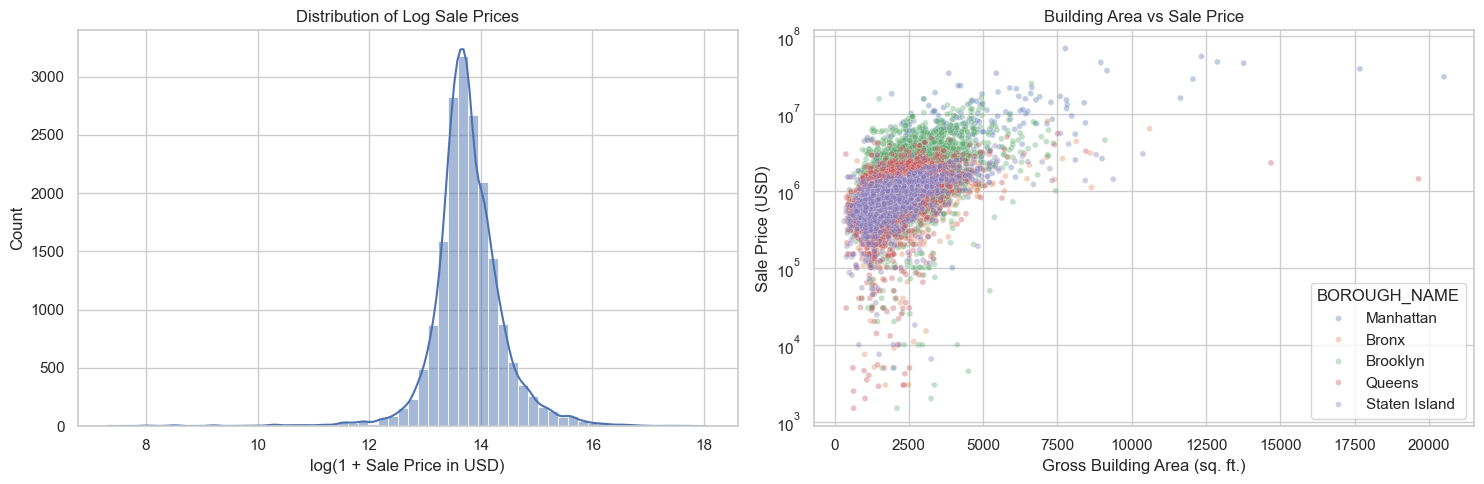

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Target distribution
sns.histplot(
    np.log1p(clean_df["SALE_PRICE_NUM"].astype(float)),
    bins=60,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Log Sale Prices")
axes[0].set_xlabel("log(1 + Sale Price in USD)")

# Feature vs target
sns.scatterplot(
    data=clean_df,
    x="GROSS SQUARE FEET_NUM",
    y="SALE_PRICE_NUM",
    hue="BOROUGH_NAME",
    alpha=0.35,
    s=18,
    ax=axes[1]
)

axes[1].set_title("Building Area vs Sale Price")
axes[1].set_xlabel("Gross Building Area (sq. ft.)")
axes[1].set_ylabel("Sale Price (USD)")
axes[1].set_yscale("log")

plt.tight_layout()
save_chart("price_distribution_and_building_area", "eda")


**Finding:** Sale prices are right-skewed, and building area has a positive but highly variable relationship with price. Log scaling helps show typical sales alongside expensive properties.


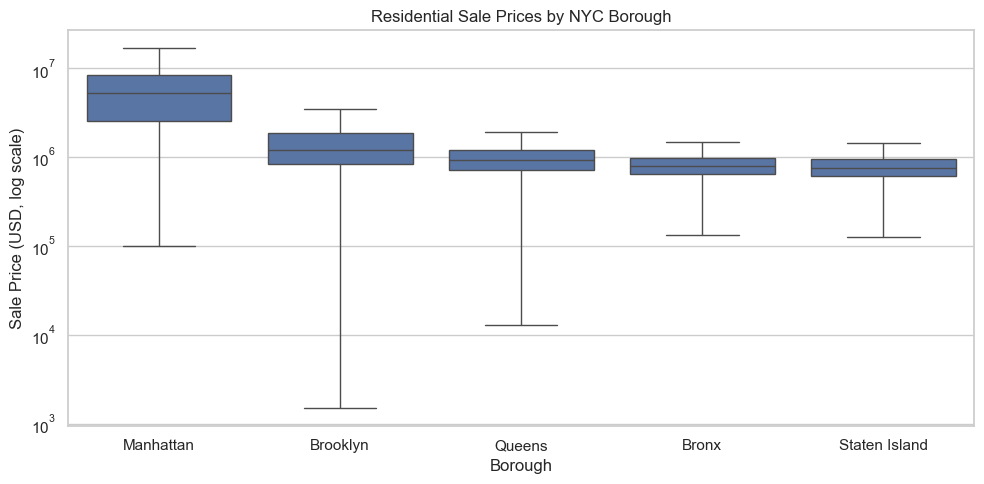

In [14]:

plt.figure(figsize=(10, 5))

order = (
    clean_df.groupby("BOROUGH_NAME")["SALE_PRICE_NUM"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=clean_df,
    x="BOROUGH_NAME",
    y="SALE_PRICE_NUM",
    order=order,
    showfliers=False
)

plt.yscale("log")
plt.title("Residential Sale Prices by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Sale Price (USD, log scale)")
plt.tight_layout()
save_chart("sale_price_by_borough", "eda")


**EDA takeaway:** Borough prices differ substantially. Compare medians rather than interpreting the highest sale as representative of a borough.

## 3. Engineer useful features

Added property age, land/building ratios, area per unit, density, sale month and log area, plus borough, neighborhood and ZIP code. These are property or sale-time attributes; no price-derived features enter the predictors.

In [15]:

# Create a working copy
feature_df = clean_df.copy()

# Standardize numeric columns for modeling
feature_df["sale_price"] = feature_df["SALE_PRICE_NUM"].astype(float)
feature_df["gross_sqft"] = feature_df["GROSS SQUARE FEET_NUM"].astype(float)
feature_df["land_sqft"] = feature_df["LAND SQUARE FEET_NUM"].astype(float)
feature_df["year_built"] = feature_df["YEAR BUILT_NUM"].astype(float)

feature_df["residential_units"] = (
    feature_df["RESIDENTIAL UNITS_NUM"].astype(float)
)

feature_df["commercial_units"] = (
    feature_df["COMMERCIAL UNITS_NUM"].astype(float)
)

feature_df["total_units"] = (
    feature_df["TOTAL UNITS_NUM"].astype(float)
)

# 1. Property age at transaction
feature_df["sale_year"] = feature_df["SALE_DATE_DT"].dt.year

feature_df["property_age"] = (
    feature_df["sale_year"] - feature_df["year_built"]
)

# Flag impossible construction years
feature_df.loc[
    (feature_df["property_age"] < 0) |
    (feature_df["property_age"] > 250),
    "property_age"
] = np.nan

# 2. Building-to-land ratio
feature_df["building_land_ratio"] = (
    feature_df["gross_sqft"] / feature_df["land_sqft"]
)

# 3. Average building area per residential unit
feature_df["area_per_unit"] = (
    feature_df["gross_sqft"] /
    feature_df["residential_units"].replace(0, np.nan)
)

# 4. Residential units per 1,000 sq. ft. of land
feature_df["residential_density"] = (
    feature_df["residential_units"] /
    feature_df["land_sqft"] * 1000
)

# 5. Transaction timing
feature_df["sale_month"] = (
    feature_df["SALE_DATE_DT"].dt.month
)

feature_df["sale_quarter"] = (
    feature_df["SALE_DATE_DT"].dt.quarter
)

# 6. Location features
feature_df["borough"] = feature_df["BOROUGH_NAME"]
feature_df["neighborhood"] = (
    feature_df["NEIGHBORHOOD"].astype(str).str.strip()
)

feature_df["zip_code"] = (
    feature_df["ZIP CODE"]
    .astype("Int64")
    .astype("string")
)

feature_df["property_type"] = (
    feature_df["BUILDING CLASS CATEGORY"]
    .astype(str)
    .str.strip()
)

print("Feature engineering complete.")
print("Rows:", len(feature_df))
print("Columns:", feature_df.shape[1])


Feature engineering complete.
Rows: 18599
Columns: 47


In [16]:

engineered_features = [
    "property_age",
    "building_land_ratio",
    "area_per_unit",
    "residential_density",
    "sale_month",
    "sale_quarter"
]

# Replace infinite values with missing values
feature_df[engineered_features] = (
    feature_df[engineered_features]
    .replace([np.inf, -np.inf], np.nan)
)

# Numerical summary
display(
    feature_df[engineered_features]
    .describe(percentiles=[0.01, 0.5, 0.99])
    .T
)

# Missingness check
display(
    feature_df[engineered_features]
    .isna()
    .sum()
    .to_frame("Missing Values")
)

# Check physically unusual engineered values
quality_checks = {
    "Negative property ages": (
        feature_df["property_age"] < 0
    ).sum(),
    "Building/land ratio above 5": (
        feature_df["building_land_ratio"] > 5
    ).sum(),
    "Area per unit below 200 sqft": (
        feature_df["area_per_unit"] < 200
    ).sum(),
    "Residential units equal to zero": (
        feature_df["residential_units"] == 0
    ).sum()
}

display(
    pd.DataFrame(
        quality_checks.items(),
        columns=["Check", "Count"]
    )
)


,count,mean,std,min,1%,50%,99%,max
property_age,"18,584.00",83.99,30.70,0.00,2.00,95.00,127.00,226.00
building_land_ratio,"18,599.00",0.80,0.51,0.01,0.17,0.66,2.63,10.77
area_per_unit,"18,598.00","1,371.74",734.36,260.00,543.29,"1,216.00","4,160.48","20,507.00"
residential_density,"18,599.00",0.65,0.42,0.00,0.10,0.53,2.00,4.43
sale_month,"18,599.00",6.62,3.47,1.00,1.00,7.00,12.00,12.00
sale_quarter,"18,599.00",2.54,1.13,1.00,1.00,3.00,4.00,4.00


,Missing Values
property_age,15
building_land_ratio,0
area_per_unit,1
residential_density,0
sale_month,0
sale_quarter,0


,Check,Count
0,Negative property ages,0
1,Building/land ratio above 5,5
2,Area per unit below 200 sqft,0
3,Residential units equal to zero,1


In [17]:

# Target
TARGET = "sale_price"

# Original structural predictors
base_numeric = [
    "gross_sqft",
    "land_sqft",
    "residential_units",
    "commercial_units",
    "year_built"
]

base_categorical = [
    "property_type"
]

# Engineered predictors
engineered_numeric = [
    "property_age",
    "building_land_ratio",
    "area_per_unit",
    "residential_density",
    "sale_month"
]

# Geographic predictors
location_categorical = [
    "borough",
    "neighborhood",
    "zip_code"
]

feature_groups = {
    "A_structural": base_numeric + base_categorical,
    "B_engineered": (
        base_numeric
        + engineered_numeric
        + base_categorical
    ),
    "C_location": (
        base_numeric
        + engineered_numeric
        + base_categorical
        + location_categorical
    )
}

for experiment, columns in feature_groups.items():
    print(f"{experiment}: {len(columns)} features")


A_structural: 6 features
B_engineered: 11 features
C_location: 14 features


In [18]:

# Log transformations to reduce skewness in area features
feature_df["log_gross_sqft"] = np.log1p(
    feature_df["gross_sqft"].clip(lower=0)
)

feature_df["log_land_sqft"] = np.log1p(
    feature_df["land_sqft"].clip(lower=0)
)

# Residential units relative to building area
feature_df["units_per_1000_building_sqft"] = (
    1000 * feature_df["residential_units"]
    / feature_df["gross_sqft"]
)

feature_df["units_per_1000_building_sqft"] = (
    feature_df["units_per_1000_building_sqft"]
    .replace([np.inf, -np.inf], np.nan)
)

# Extend our engineered-feature experiment
engineered_numeric += [
    "log_gross_sqft",
    "log_land_sqft",
    "units_per_1000_building_sqft"
]

# Avoid duplicate feature names when rerunning cells
engineered_numeric = list(dict.fromkeys(engineered_numeric))

feature_groups["B_engineered"] = (
    base_numeric + engineered_numeric + base_categorical
)

feature_groups["C_location"] = (
    feature_groups["B_engineered"] + location_categorical
)

print("Engineered predictors:", len(feature_groups["B_engineered"]))
print("Location-enhanced predictors:", len(feature_groups["C_location"]))


Engineered predictors: 14
Location-enhanced predictors: 17


### EDA: Which predictors overlap?

Spearman correlations show where engineered variables repeat similar information. Strong correlations help explain why ranking features one at a time may be misleading.

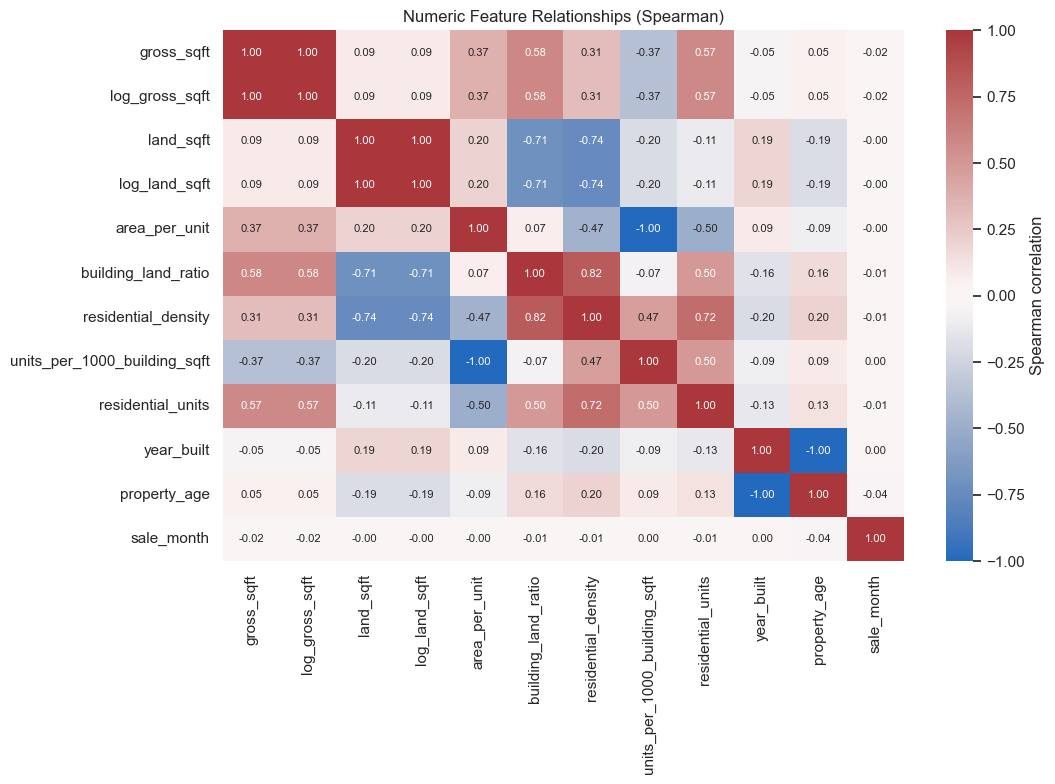

Strongest overlapping numeric features:


,feature_1,feature_2,spearman_r,abs_r
0,gross_sqft,log_gross_sqft,1.00,1.00
21,land_sqft,log_land_sqft,1.00,1.00
40,area_per_unit,units_per_1000_building_sqft,-1.00,1.00
63,year_built,property_age,-1.00,1.00
45,building_land_ratio,residential_density,0.82,0.82
32,log_land_sqft,residential_density,-0.74,0.74
24,land_sqft,residential_density,-0.74,0.74
52,residential_density,residential_units,0.72,0.72


In [19]:
# EDA: check redundancy among numerical predictors (no sale-price-derived features)
corr_cols = [
    "gross_sqft", "log_gross_sqft", "land_sqft", "log_land_sqft",
    "area_per_unit", "building_land_ratio", "residential_density",
    "units_per_1000_building_sqft", "residential_units",
    "year_built", "property_age", "sale_month"
]

numeric_eda = feature_df[corr_cols].replace([np.inf, -np.inf], np.nan)
spearman_corr = numeric_eda.corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(
    spearman_corr,
    cmap="vlag", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    square=False, cbar_kws={"label": "Spearman correlation"}
)
plt.title("Numeric Feature Relationships (Spearman)")
plt.tight_layout()
save_chart("numeric_feature_correlations", "eda")

# Unique feature pairs, sorted by absolute correlation
upper_mask = np.triu(np.ones(spearman_corr.shape, dtype=bool), k=1)
strong_pairs = (
    spearman_corr.where(upper_mask)
    .stack()
    .rename("spearman_r")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)
strong_pairs["abs_r"] = strong_pairs["spearman_r"].abs()
strong_pairs = strong_pairs.sort_values("abs_r", ascending=False)
print("Strongest overlapping numeric features:")
display(strong_pairs.head(8).round(3))
strong_pairs.to_csv(
    RESULTS_DIR / "feature_analysis" / "numeric_feature_correlations.csv",
    index=False
)


**Finding:** Gross area and log gross area are redundant by design; the same applies to land area and its log. Correlation indicates overlap, not that one feature must be deleted.

## 4. Prevent leakage

We split by borough–block–lot property ID, keeping repeated transactions for the same property together. Preprocessing and feature selection are fit on training data, not the test set.

In [20]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

RANDOM_STATE = 42

# Clean NYC property identifiers (e.g., "1,857" -> 1857)
for col in ["BOROUGH", "BLOCK", "LOT"]:
    feature_df[col] = pd.to_numeric(
        feature_df[col].astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    ).astype("Int64")

# Ensure all properties have valid identifiers
assert feature_df[["BOROUGH", "BLOCK", "LOT"]].notna().all().all(), \
    "Missing or invalid property identifiers found"

# Create property-level group ID
feature_df["property_id"] = (
    feature_df["BOROUGH"].astype(str) + "_"
    + feature_df["BLOCK"].astype(str) + "_"
    + feature_df["LOT"].astype(str)
)

# Select all engineered predictors
all_features = feature_groups["C_location"]

X = feature_df[all_features].copy()
y = feature_df["sale_price"].copy()
groups = feature_df["property_id"]

# Split by property to prevent repeated-property leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Validation
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert X_train.shape[1] == 17

train_groups = set(feature_df.loc[X_train.index, "property_id"])
test_groups = set(feature_df.loc[X_test.index, "property_id"])

assert train_groups.isdisjoint(test_groups)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print(f"Predictors: {X_train.shape[1]}")
print(f"Shared properties: {len(train_groups & test_groups)}")
print("Group-aware split successful!")


Training rows: 14,886
Testing rows: 3,713
Predictors: 17
Shared properties: 0
Group-aware split successful!


In [21]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_regression

# Confirm the latest engineered features are in the split
all_features = feature_groups["C_location"]

assert set(all_features).issubset(X_train.columns), (
    "Rerun the group-aware split using the expanded C_location features."
)

numeric_features = [
    col for col in all_features
    if col in base_numeric + engineered_numeric
]

categorical_features = [
    col for col in all_features
    if col in base_categorical + location_categorical
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))
print("Total original predictors:", len(all_features))


Numerical predictors: 13
Categorical predictors: 4
Total original predictors: 17


## 5. Feature selection

SelectKBest tests individual relationships with sale price. We also compare using all encoded features because the top-ranked 20 may miss useful combined neighborhood signals.

In [22]:

# Fit preprocessing ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Encoded feature names
encoded_feature_names = (
    preprocessor.get_feature_names_out()
)

# Select the top 20 encoded features
k = min(20, len(encoded_feature_names))

selector = SelectKBest(
    score_func=f_regression,
    k=k
)

selector.fit(X_train_processed, y_train)

feature_scores = pd.DataFrame({
    "Feature": encoded_feature_names,
    "F_Score": selector.scores_,
    "P_Value": selector.pvalues_,
    "Selected": selector.get_support()
})

feature_scores["F_Score"] = (
    feature_scores["F_Score"]
    .replace([np.inf, -np.inf], np.nan)
)

feature_scores = feature_scores.sort_values(
    "F_Score",
    ascending=False
)

print("Total encoded features:", len(encoded_feature_names))
print("Selected features:", selector.get_support().sum())

display(feature_scores.head(25))

# Save the complete scoring table
output_dir = RESULTS_DIR / "feature_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

feature_scores.to_csv(
    output_dir / "feature_selection_scores.csv",
    index=False
)

print("Feature scores saved.")


Total encoded features: 411
Selected features: 20


,Feature,F_Score,P_Value,Selected
0,numeric__gross_sqft,"5,114.22",0.00,True
18,categorical__borough_Manhattan,"4,599.67",0.00,True
7,numeric__area_per_unit,"4,561.36",0.00,True
10,numeric__log_gross_sqft,"2,753.80",0.00,True
6,numeric__building_land_ratio,"2,563.58",0.00,True
115,categorical__neighborhood_GREENWICH VILLAGE-WEST,"2,388.75",0.00,True
256,categorical__zip_code_10014,"1,882.26",0.00,True
227,categorical__neighborhood_UPPER EAST SIDE (79-96),"1,267.57",0.00,True
226,categorical__neighborhood_UPPER EAST SIDE (59-79),994.72,0.00,True
275,categorical__zip_code_10075,706.36,0.00,True


Feature scores saved.


## 6. Establish a baseline

We compare against a median-price predictor and regularized linear regression using group-aware cross-validation. This gives the ensemble models a meaningful benchmark.

In [23]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone

# Groups aligned to the training records
train_property_groups = feature_df.loc[
    X_train.index, "property_id"
]

cv = GroupKFold(n_splits=3)

models = {
    "Median Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0)
}

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for name, model in models.items():

    if name == "Median Baseline":
        pipeline = Pipeline([
            ("model", clone(model))
        ])

        X_cv = X_train[["gross_sqft"]]

    else:
        pipeline = Pipeline([
            ("preprocessing", clone(preprocessor)),
            ("selection", SelectKBest(
                score_func=f_regression,
                k=k
            )),
            ("model", clone(model))
        ])

        X_cv = X_train

    scores = cross_validate(
        pipeline,
        X_cv,
        y_train,
        cv=cv,
        groups=train_property_groups,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean(),
        "R2_Std": scores["test_R2"].std()
    })

baseline_results = pd.DataFrame(
    cv_results
).sort_values("CV_MAE")

display(baseline_results.round(4))

baseline_results.to_csv(
    RESULTS_DIR / "model_comparison" /
    "baseline_cv_results.csv",
    index=False
)


,Model,CV_MAE,CV_RMSE,CV_R2,R2_Std
1,Linear Regression,"434,412.91","1,035,552.41",0.51,0.07
2,Ridge Regression,"440,381.53","1,022,161.95",0.53,0.05
0,Median Baseline,"537,215.95","1,523,942.58",-0.04,0.01


**Feature-selection finding:** Full-feature Ridge reached **$338,010 CV MAE**, versus **$440,382** with the top 20 encoded features. `f_regression` scores each encoded column *separately*, so correlated features can rank highly together, while nonlinear effects and useful combinations can be missed. The top 20 also excluded many location indicators. We kept all 17 original predictors for the final comparison based on group-aware CV, not F-scores alone.

In [24]:

from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone

# Identical folds for every experiment
cv = GroupKFold(n_splits=3)

train_groups = feature_df.loc[
    X_train.index, "property_id"
]

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

def make_ridge_pipeline(select_features=False, log_target=False):
    steps = [
        ("preprocessing", clone(preprocessor))
    ]

    if select_features:
        steps.append((
            "selection",
            SelectKBest(f_regression, k=20)
        ))

    steps.append(("model", Ridge(alpha=10.0)))

    pipeline = Pipeline(steps)

    if log_target:
        return TransformedTargetRegressor(
            regressor=pipeline,
            func=np.log1p,
            inverse_func=np.expm1,
            check_inverse=True
        )

    return pipeline


experiments = {
    "Ridge - All Features":
        make_ridge_pipeline(),

    "Ridge - Top 20 Features":
        make_ridge_pipeline(select_features=True),

    "Ridge - Log Target":
        make_ridge_pipeline(log_target=True),

    "Ridge - Top 20 + Log Target":
        make_ridge_pipeline(
            select_features=True,
            log_target=True
        )
}

experiment_results = []

for name, estimator in experiments.items():
    print(f"Evaluating: {name}")

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    experiment_results.append({
        "Experiment": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean(),
        "R2_Std": scores["test_R2"].std()
    })

experiment_df = (
    pd.DataFrame(experiment_results)
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

display(experiment_df.round(3))

experiment_df.to_csv(
    RESULTS_DIR / "model_comparison" /
    "experiment_1_feature_selection_log_target.csv",
    index=False
)


Evaluating: Ridge - All Features
Evaluating: Ridge - Top 20 Features
Evaluating: Ridge - Log Target
Evaluating: Ridge - Top 20 + Log Target


,Experiment,CV_MAE,CV_RMSE,CV_R2,R2_Std
0,Ridge - Log Target,"317,093.96","1,203,829.86",0.30,0.46
1,Ridge - All Features,"338,010.27","939,170.62",0.61,0.04
2,Ridge - Top 20 + Log Target,"402,125.60","1,392,779.38",0.02,0.77
3,Ridge - Top 20 Features,"440,381.53","1,022,161.95",0.53,0.05


## 7. Test nonlinear models

Ridge, Random Forest and Extra Trees are compared on the same group-aware CV folds. Extra Trees led with **$306,754 CV MAE** and **0.69 CV R²** (150-tree comparison).

In [25]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.base import clone

# Full 17-feature dataset
model_features = feature_groups["C_location"]

train_groups = feature_df.loc[
    X_train.index, "property_id"
]

cv = GroupKFold(n_splits=3)

advanced_models = {
    "Ridge": Ridge(alpha=10.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

advanced_results = []

for name, model in advanced_models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train[model_features],
        y_train,
        groups=train_groups,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    advanced_results.append({
        "Model": name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean(),
        "R2_Std": scores["test_R2"].std()
    })

    print(f"Completed: {name}")

advanced_results_df = (
    pd.DataFrame(advanced_results)
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

display(advanced_results_df.round(3))

advanced_results_df.to_csv(
    RESULTS_DIR / "model_comparison" /
    "advanced_model_results.csv",
    index=False
)


Completed: Ridge
Completed: Random Forest
Completed: Extra Trees


,Model,CV_MAE,CV_RMSE,CV_R2,R2_Std
0,Extra Trees,"306,754.19","827,266.03",0.69,0.06
1,Random Forest,"321,537.27","886,569.27",0.65,0.04
2,Ridge,"338,010.27","939,170.62",0.61,0.04


## 8. Lightweight tuning

We tested four smaller Extra Trees configurations to avoid an expensive search. Depth **25**, minimum leaf size **2** gave the best CV MAE (**$301,943**) in this 60-tree experiment.

In [26]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import pandas as pd

# Four targeted configurations
configs = [
    {"max_depth": 15, "min_samples_leaf": 3},
    {"max_depth": 20, "min_samples_leaf": 3},
    {"max_depth": 25, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 4}
]

train_groups = feature_df.loc[X_train.index, "property_id"]
cv = GroupKFold(n_splits=3)

tuning_results = []

for config in configs:
    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", ExtraTreesRegressor(
            n_estimators=60,
            max_depth=config["max_depth"],
            min_samples_leaf=config["min_samples_leaf"],
            max_features=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    tuning_results.append({
        **config,
        "CV_MAE": -scores["test_score"].mean()
    })

results_df = pd.DataFrame(tuning_results).sort_values("CV_MAE")

display(results_df)

results_df.to_csv(
    RESULTS_DIR / "model_comparison" / "fast_tuning.csv",
    index=False
)


,max_depth,min_samples_leaf,CV_MAE
2,25.00,2,"301,942.71"
3,NaN,4,"304,164.90"
1,20.00,3,"307,092.39"
0,15.00,3,"319,319.84"


## 9. Final holdout evaluation

The chosen 60-tree Extra Trees model achieved **$309,109 MAE**, **$910,918 RMSE**, **0.728 R²** and **$143,010 median absolute error** on **3,713** unseen transactions. Its MAE was **44.64% lower** than the median-price baseline.

In [27]:

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

# Configuration selected using training-only CV
best_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", ExtraTreesRegressor(
        n_estimators=60,
        max_depth=25,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train on the complete training set
best_model.fit(X_train, y_train)

# Predict ONLY on the untouched holdout set
y_pred = best_model.predict(X_test)

# Final metrics in original USD
final_metrics = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred),
    "Median_AE": median_absolute_error(y_test, y_pred)
}

print("FINAL HOLDOUT TEST RESULTS")
print("=" * 45)

for metric, value in final_metrics.items():
    if metric == "R2":
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: ${value:,.2f}")

# Compare against a median-price baseline
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy="median")
dummy.fit(X_train[["gross_sqft"]], y_train)

dummy_pred = dummy.predict(X_test[["gross_sqft"]])

baseline_mae = mean_absolute_error(y_test, dummy_pred)

print(f"\nMedian baseline MAE: ${baseline_mae:,.2f}")
print(
    "MAE improvement over median baseline: "
    f"{(1 - final_metrics['MAE'] / baseline_mae) * 100:.2f}%"
)

pd.DataFrame([final_metrics]).to_csv(
    RESULTS_DIR / "evaluation" / "final_model_metrics.csv",
    index=False
)


FINAL HOLDOUT TEST RESULTS
MAE: $309,108.55
RMSE: $910,917.63
R2: 0.7280
Median_AE: $143,010.12

Median baseline MAE: $558,332.14
MAE improvement over median baseline: 44.64%


**Where it fails:** Errors rise from **$265K MAE** for one-family homes to **$416K** for three-family homes. The model overpredicts sub-$500K sales and underpredicts sales above $2M; expensive properties contribute large errors.

In [28]:

# Build an evaluation dataset aligned with test transactions
evaluation_df = feature_df.loc[X_test.index, [
    "property_id",
    "borough",
    "property_type",
    "gross_sqft",
    "sale_price"
]].copy()

evaluation_df["predicted_price"] = y_pred

evaluation_df["error"] = (
    evaluation_df["predicted_price"]
    - evaluation_df["sale_price"]
)

evaluation_df["absolute_error"] = (
    evaluation_df["error"].abs()
)

evaluation_df["percentage_error"] = (
    evaluation_df["absolute_error"]
    / evaluation_df["sale_price"] * 100
)

# Borough-level performance
borough_errors = (
    evaluation_df.groupby("borough")
    .agg(
        Transactions=("sale_price", "size"),
        Actual_Median=("sale_price", "median"),
        MAE=("absolute_error", "mean"),
        Median_AE=("absolute_error", "median"),
        Median_APE=("percentage_error", "median"),
        Bias=("error", "mean")
    )
    .sort_values("MAE", ascending=False)
)

print("ERROR ANALYSIS BY BOROUGH")
display(borough_errors.round(2))

# Property-type performance
property_errors = (
    evaluation_df.groupby("property_type")
    .agg(
        Transactions=("sale_price", "size"),
        MAE=("absolute_error", "mean"),
        Median_AE=("absolute_error", "median"),
        Bias=("error", "mean")
    )
)

print("\nERROR ANALYSIS BY PROPERTY TYPE")
display(property_errors.round(2))

# Price segments using fixed USD thresholds
price_bins = [0, 500_000, 1_000_000, 2_000_000, np.inf]
price_labels = [
    "Under $500K",
    "$500K–$1M",
    "$1M–$2M",
    "Above $2M"
]

evaluation_df["price_segment"] = pd.cut(
    evaluation_df["sale_price"],
    bins=price_bins,
    labels=price_labels,
    include_lowest=True
)

segment_errors = (
    evaluation_df.groupby(
        "price_segment", observed=True
    )
    .agg(
        Transactions=("sale_price", "size"),
        MAE=("absolute_error", "mean"),
        Median_AE=("absolute_error", "median"),
        Bias=("error", "mean")
    )
)

print("\nERROR ANALYSIS BY PRICE SEGMENT")
display(segment_errors.round(2))

# Save numerical results
borough_errors.to_csv(
    RESULTS_DIR / "evaluation" / "errors_by_borough.csv"
)

property_errors.to_csv(
    RESULTS_DIR / "evaluation" / "errors_by_property_type.csv"
)

segment_errors.to_csv(
    RESULTS_DIR / "evaluation" / "errors_by_price_segment.csv"
)


ERROR ANALYSIS BY BOROUGH


,Transactions,Actual_Median,MAE,Median_AE,Median_APE,Bias
borough,,,,,,
Manhattan,47,"5,850,000.00","3,380,586.84","1,498,588.55",24.20,"-1,285,396.89"
Brooklyn,1040,"1,195,000.00","467,879.31","235,789.34",18.83,"-18,557.03"
Queens,1620,"905,000.00","206,625.59","133,076.07",14.02,"2,263.85"
Bronx,398,"800,000.00","178,184.80","120,368.39",14.85,"-15,002.09"
Staten Island,608,"770,000.00","158,860.18","87,830.40",11.22,"4,210.40"



ERROR ANALYSIS BY PROPERTY TYPE


,Transactions,MAE,Median_AE,Bias
property_type,,,,
01 ONE FAMILY DWELLINGS,1880,"264,997.99","115,527.47","-30,187.06"
02 TWO FAMILY DWELLINGS,1477,"339,373.86","173,578.84","-22,273.24"
03 THREE FAMILY DWELLINGS,356,"416,484.95","242,399.35","28,631.51"



ERROR ANALYSIS BY PRICE SEGMENT


,Transactions,MAE,Median_AE,Bias
price_segment,,,,
Under $500K,339,"477,601.93","379,937.62","475,839.21"
$500K–$1M,1930,"142,819.45","91,333.68","62,675.05"
$1M–$2M,1130,"237,399.15","185,422.52","-93,971.61"
Above $2M,314,"1,407,358.04","776,611.31","-813,824.35"


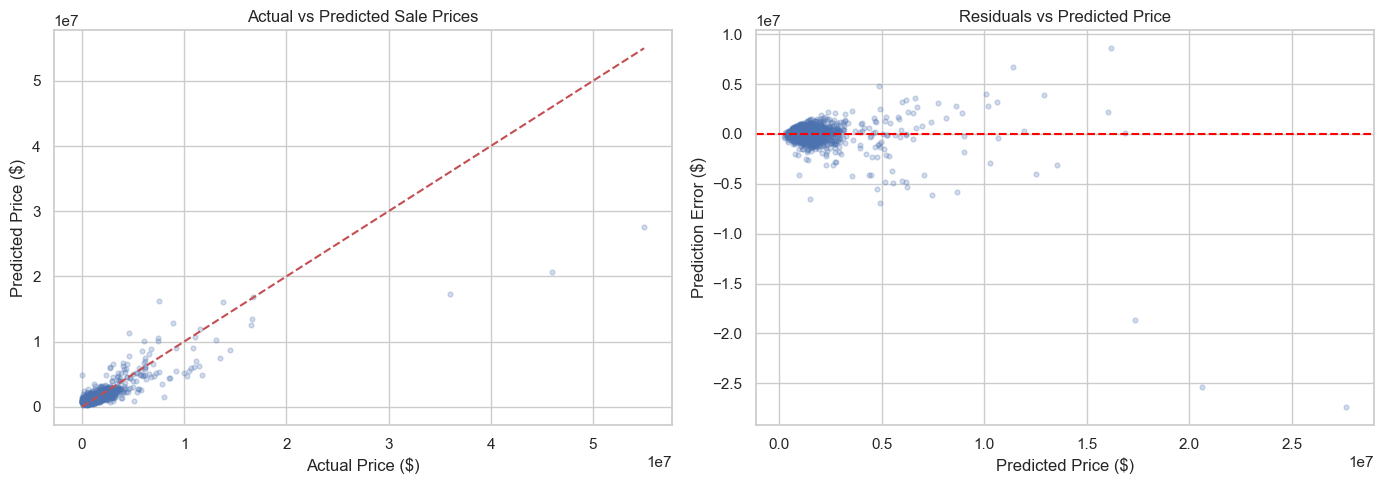

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs predicted prices
axes[0].scatter(
    y_test,
    y_pred,
    alpha=0.25,
    s=12
)

max_price = max(y_test.max(), y_pred.max())

axes[0].plot(
    [0, max_price],
    [0, max_price],
    "r--",
    linewidth=1.5
)

axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].set_title("Actual vs Predicted Sale Prices")

# Residual diagnostics
axes[1].scatter(
    y_pred,
    evaluation_df["error"],
    alpha=0.25,
    s=12
)

axes[1].axhline(0, color="red", linestyle="--")

axes[1].set_xlabel("Predicted Price ($)")
axes[1].set_ylabel("Prediction Error ($)")
axes[1].set_title("Residuals vs Predicted Price")

plt.tight_layout()
save_chart("final_prediction_diagnostics", "evaluation")


## 10. What drives predictions?

Tree importance ranks borough (**28.91%**), neighborhood (**15.73%**) and ZIP (**8.94%**) highest—**53.58% combined**. These are model importance scores, **not causal price effects**; correlated geography features can share importance.

In [30]:

# Extract fitted preprocessing and model
fitted_preprocessor = best_model.named_steps["preprocessing"]
fitted_tree = best_model.named_steps["model"]

encoded_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_tree.feature_importances_

assert len(encoded_names) == len(importances)

# Map encoded features to original predictors
def original_feature_name(encoded_name):
    if encoded_name.startswith("numeric__"):
        return encoded_name.replace("numeric__", "", 1)

    if encoded_name.startswith("categorical__"):
        name = encoded_name.replace("categorical__", "", 1)

        for col in sorted(
            categorical_features,
            key=len,
            reverse=True
        ):
            if name.startswith(col + "_"):
                return col

    return encoded_name

importance_df = pd.DataFrame({
    "Encoded_Feature": encoded_names,
    "Original_Feature": [
        original_feature_name(name)
        for name in encoded_names
    ],
    "Importance": importances
})

# Aggregate encoded importance to original predictors
grouped_importance = (
    importance_df
    .groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_importance["Importance_%"] = (
    grouped_importance["Importance"] * 100
)

display(grouped_importance.round(3))

grouped_importance.to_csv(
    RESULTS_DIR / "feature_analysis" /
    "extra_trees_feature_importance.csv",
    index=False
)


,Original_Feature,Importance,Importance_%
0,borough,0.29,28.91
1,neighborhood,0.16,15.73
2,log_gross_sqft,0.09,9.34
3,zip_code,0.09,8.94
4,area_per_unit,0.09,8.85
5,gross_sqft,0.08,7.85
6,residential_density,0.04,3.97
7,land_sqft,0.04,3.78
8,units_per_1000_building_sqft,0.03,3.16
9,log_land_sqft,0.02,2.04


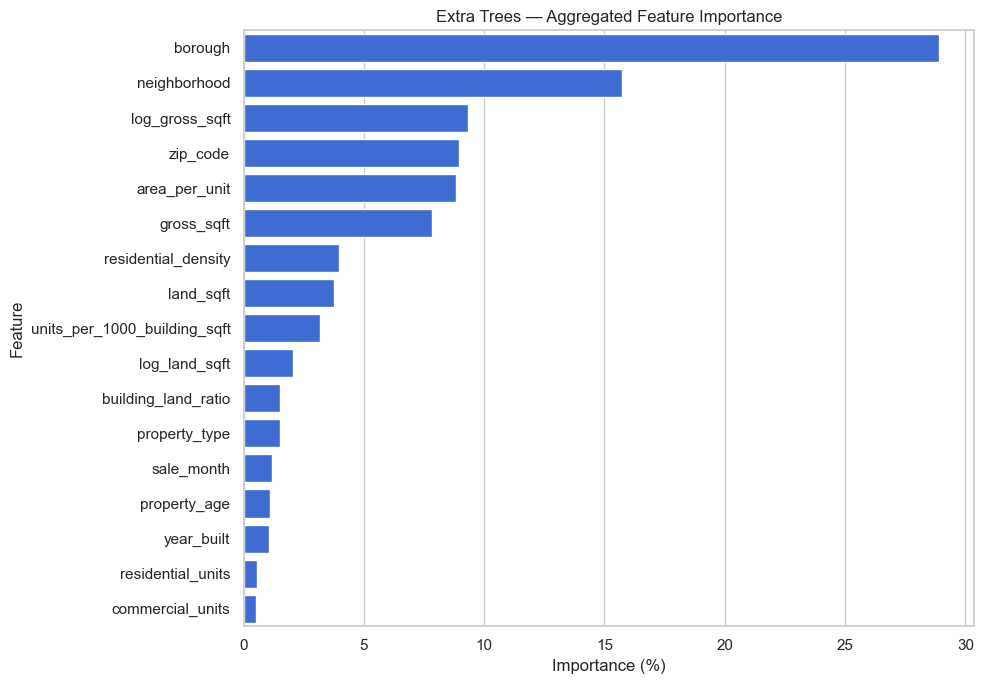

In [31]:

plt.figure(figsize=(10, 7))

sns.barplot(
    data=grouped_importance,
    x="Importance_%",
    y="Original_Feature",
    color="#2563EB"
)

plt.title("Extra Trees — Aggregated Feature Importance")
plt.xlabel("Importance (%)")
plt.ylabel("Feature")

plt.tight_layout()
save_chart(
    "extra_trees_feature_importance",
    "feature_analysis"
)


## 11. Neighborhood market intelligence

Median price per gross square foot is **$535.71**, but varies sharply. Greenwich Village-West reached **$3,130/sqft** versus **$312/sqft** in Melrose/Concourse among neighborhoods with at least 30 screened sales. This is descriptive analysis, not a model feature.

In [32]:

# Use the cleaned dataset, not the model predictions
market_df = feature_df.copy()

# Price per square foot: analysis only, NEVER a model predictor
market_df["price_per_sqft"] = (
    market_df["sale_price"] / market_df["gross_sqft"]
)

# Descriptive distribution and tail behavior
print("PRICE DISTRIBUTION")
print("Skewness:", round(market_df["sale_price"].skew(), 3))
print("Excess kurtosis:", round(market_df["sale_price"].kurt(), 3))

display(
    market_df["price_per_sqft"].describe(
        percentiles=[.01, .05, .25, .50, .75, .95, .99]
    )
)

# Borough + neighborhood aggregation
market_summary = (
    market_df
    .groupby(["borough", "neighborhood"])
    .agg(
        transactions=("sale_price", "size"),
        median_price=("sale_price", "median"),
        mean_price=("sale_price", "mean"),
        median_price_per_sqft=("price_per_sqft", "median"),
        price_q25=("sale_price", lambda x: x.quantile(.25)),
        price_q75=("sale_price", lambda x: x.quantile(.75))
    )
    .reset_index()
)

# Robust measure of neighborhood price dispersion
market_summary["price_iqr"] = (
    market_summary["price_q75"] -
    market_summary["price_q25"]
)

# Require sufficient transaction volume
reliable_neighborhoods = market_summary.loc[
    market_summary["transactions"] >= 30
].copy()

print("\nMOST EXPENSIVE NEIGHBORHOODS BY MEDIAN PRICE/SQFT")
display(
    reliable_neighborhoods.nlargest(
        15, "median_price_per_sqft"
    )[
        ["borough", "neighborhood",
         "transactions", "median_price",
         "median_price_per_sqft", "price_iqr"]
    ]
)

print("\nMOST AFFORDABLE NEIGHBORHOODS BY MEDIAN PRICE/SQFT")
display(
    reliable_neighborhoods.nsmallest(
        15, "median_price_per_sqft"
    )[
        ["borough", "neighborhood",
         "transactions", "median_price",
         "median_price_per_sqft", "price_iqr"]
    ]
)

# Export results
output = RESULTS_DIR / "eda"
output.mkdir(parents=True, exist_ok=True)

market_summary.to_csv(
    output / "nyc_neighborhood_market_intelligence.csv",
    index=False
)

print("\nNeighborhood groups analyzed:", len(market_summary))
print("Groups with at least 30 transactions:",
      len(reliable_neighborhoods))


PRICE DISTRIBUTION
Skewness: 16.453
Excess kurtosis: 471.694


count   18,599.00
mean       600.89
std        389.31
min          0.62
1%          80.08
5%         232.09
25%        407.30
50%        535.71
75%        696.24
95%      1,139.38
99%      2,028.61
max     10,333.33
Name: price_per_sqft, dtype: float64


MOST EXPENSIVE NEIGHBORHOODS BY MEDIAN PRICE/SQFT


,borough,neighborhood,transactions,median_price,median_price_per_sqft,price_iqr
98,Manhattan,GREENWICH VILLAGE-WEST,31,"9,415,000.00","3,130.41","9,725,000.00"
112,Manhattan,UPPER EAST SIDE (59-79),35,"8,550,000.00","1,822.92","8,350,000.00"
39,Brooklyn,BOERUM HILL,45,"3,750,000.00","1,346.77","1,790,000.00"
47,Brooklyn,CARROLL GARDENS,41,"4,000,000.00","1,346.73","2,004,500.00"
80,Brooklyn,PARK SLOPE,118,"4,197,500.00","1,327.50","2,778,750.00"
66,Brooklyn,GOWANUS,33,"2,100,000.00","1,326.65","1,244,313.00"
48,Brooklyn,CLINTON HILL,35,"3,600,000.00","1,299.83","1,575,000.00"
88,Brooklyn,WILLIAMSBURG-EAST,39,"2,505,000.00","1,290.63","1,122,290.50"
81,Brooklyn,PARK SLOPE SOUTH,33,"2,650,000.00","1,275.93","963,533.00"
64,Brooklyn,FORT GREENE,32,"3,200,000.00","1,256.94","2,668,750.00"



MOST AFFORDABLE NEIGHBORHOODS BY MEDIAN PRICE/SQFT


,borough,neighborhood,transactions,median_price,median_price_per_sqft,price_iqr
17,Bronx,MELROSE/CONCOURSE,36,"867,500.00",311.75,"307,999.75"
120,Queens,ARVERNE,89,"600,000.00",334.62,"269,888.00"
28,Bronx,SOUNDVIEW,120,"825,000.00",335.07,"392,656.50"
201,Staten Island,NEW BRIGHTON,75,"600,000.00",338.45,"202,500.00"
2,Bronx,BEDFORD PARK/NORWOOD,58,"975,000.00",338.69,"434,125.00"
32,Bronx,WILLIAMSBRIDGE,145,"750,000.00",347.97,"395,000.00"
22,Bronx,PARKCHESTER,32,"769,125.00",352.57,"351,250.00"
220,Staten Island,STAPLETON,56,"545,000.00",354.60,"293,750.00"
13,Bronx,HIGHBRIDGE/MORRIS HEIGHTS,30,"867,500.00",355.22,"418,750.00"
19,Bronx,MORRISANIA/LONGWOOD,96,"848,500.00",362.87,"335,625.00"



Neighborhood groups analyzed: 231
Groups with at least 30 transactions: 153


### EDA: Is the location gap just property mix?

Compare median price per gross square foot across boroughs **within each property class**. Cells with fewer than 15 sales are hidden to avoid unstable comparisons.

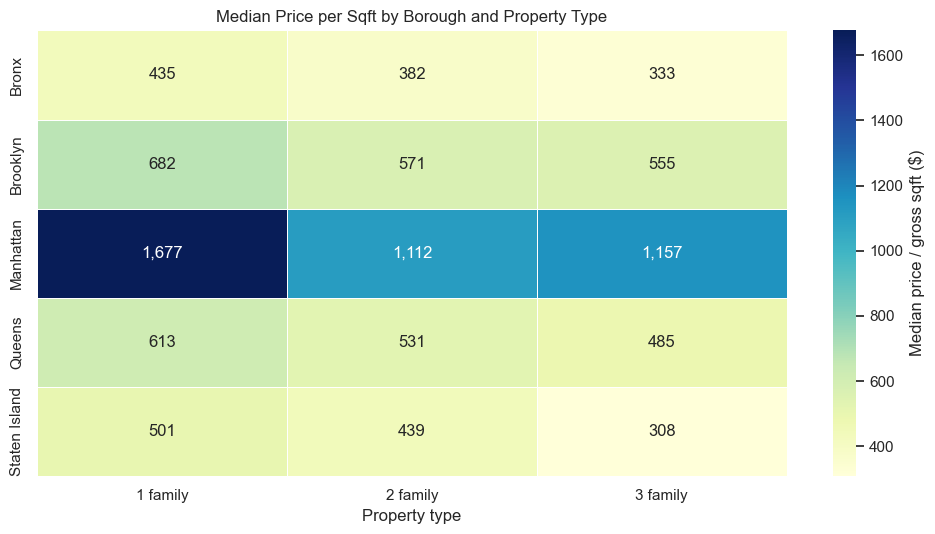

Borough/property-type PPSF summary (group size shown):


,borough,property_type,transactions,median_ppsf
0,Bronx,01 ONE FAMILY DWELLINGS,789,435.27
1,Bronx,02 TWO FAMILY DWELLINGS,921,381.84
2,Bronx,03 THREE FAMILY DWELLINGS,360,333.40
3,Brooklyn,01 ONE FAMILY DWELLINGS,1818,681.60
4,Brooklyn,02 TWO FAMILY DWELLINGS,2617,570.98
5,Brooklyn,03 THREE FAMILY DWELLINGS,861,555.28
6,Manhattan,01 ONE FAMILY DWELLINGS,123,"1,676.56"
7,Manhattan,02 TWO FAMILY DWELLINGS,81,"1,111.84"
8,Manhattan,03 THREE FAMILY DWELLINGS,39,"1,157.37"
9,Queens,01 ONE FAMILY DWELLINGS,4443,612.75


In [33]:
# EDA: compare local pricing within one-, two-, and three-family dwellings
borough_type_ppsf = (
    market_df.groupby(["borough", "property_type"], observed=True)
    .agg(
        transactions=("price_per_sqft", "size"),
        median_ppsf=("price_per_sqft", "median")
    )
    .reset_index()
)
# Avoid presenting very small borough/class groups as stable estimates
min_transactions = 15
plot_ppsf = borough_type_ppsf.copy()
plot_ppsf.loc[
    plot_ppsf["transactions"] < min_transactions, "median_ppsf"
] = np.nan

ppsf_matrix = plot_ppsf.pivot(
    index="borough", columns="property_type", values="median_ppsf"
)
ppsf_matrix = ppsf_matrix.rename(columns={
    "01 ONE FAMILY DWELLINGS": "1 family",
    "02 TWO FAMILY DWELLINGS": "2 family",
    "03 THREE FAMILY DWELLINGS": "3 family"
})

plt.figure(figsize=(10, 5.5))
sns.heatmap(
    ppsf_matrix, annot=True, fmt=",.0f", cmap="YlGnBu",
    linewidths=0.5, cbar_kws={"label": "Median price / gross sqft ($)"}
)
plt.title("Median Price per Sqft by Borough and Property Type")
plt.xlabel("Property type")
plt.ylabel("")
plt.tight_layout()
save_chart("borough_property_type_price_per_sqft", "eda")

print("Borough/property-type PPSF summary (group size shown):")
display(borough_type_ppsf.round(2))
borough_type_ppsf.to_csv(
    RESULTS_DIR / "eda" / "borough_property_type_ppsf.csv", index=False
)


**Finding:** Compare boroughs within the same family-home category rather than pooling different property types. These are descriptive differences; price per sqft uses the known sale price and is **not** a model input.

## 12. Investigate unusual sales

Borough- and property-type-specific IQR bounds flagged **781 sales (4.20%)** with unusual price per square foot. An outlier flag is a prompt to investigate—not proof of a bad record.

In [34]:

# Group-aware price-per-square-foot outlier detection
outlier_df = market_df.copy()

group_cols = ["borough", "property_type"]

# Calculate quartiles within comparable property groups
group_stats = (
    outlier_df.groupby(group_cols)["price_per_sqft"]
    .agg(
        count="count",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

group_stats["iqr"] = group_stats["q3"] - group_stats["q1"]

group_stats["lower_bound"] = (
    group_stats["q1"] - 1.5 * group_stats["iqr"]
).clip(lower=0)

group_stats["upper_bound"] = (
    group_stats["q3"] + 1.5 * group_stats["iqr"]
)

# Attach group-specific bounds
outlier_df = outlier_df.merge(
    group_stats,
    on=group_cols,
    how="left",
    validate="many_to_one"
)

# Flag statistical outliers, not confirmed errors
outlier_df["ppsf_outlier"] = (
    (outlier_df["price_per_sqft"] < outlier_df["lower_bound"])
    | (outlier_df["price_per_sqft"] > outlier_df["upper_bound"])
)

print("Total transactions:", len(outlier_df))
print("Flagged outliers:", outlier_df["ppsf_outlier"].sum())
print(
    "Outlier percentage:",
    round(outlier_df["ppsf_outlier"].mean() * 100, 2)
)

# Outlier prevalence by borough
outlier_summary = (
    outlier_df.groupby("borough")
    .agg(
        transactions=("ppsf_outlier", "size"),
        flagged=("ppsf_outlier", "sum"),
        median_ppsf=("price_per_sqft", "median")
    )
)

outlier_summary["outlier_pct"] = (
    outlier_summary["flagged"]
    / outlier_summary["transactions"] * 100
)

display(outlier_summary.round(2))

# Investigate the most extreme observations
extreme_properties = outlier_df.loc[
    outlier_df["ppsf_outlier"],
    [
        "borough",
        "neighborhood",
        "property_type",
        "sale_price",
        "gross_sqft",
        "land_sqft",
        "price_per_sqft",
        "lower_bound",
        "upper_bound"
    ]
]

print("\nTOP 15 PRICE/SQFT OBSERVATIONS")
display(
    extreme_properties.nlargest(15, "price_per_sqft")
)

print("\nBOTTOM 15 PRICE/SQFT OBSERVATIONS")
display(
    extreme_properties.nsmallest(15, "price_per_sqft")
)

# Save audit output
outlier_summary.to_csv(
    RESULTS_DIR / "eda" / "ppsf_outlier_summary.csv"
)


Total transactions: 18599
Flagged outliers: 781
Outlier percentage: 4.2


,transactions,flagged,median_ppsf,outlier_pct
borough,,,,
Bronx,2070,90,392.16,4.35
Brooklyn,5296,320,604.71,6.04
Manhattan,243,15,"1,387.82",6.17
Queens,7672,240,570.54,3.13
Staten Island,3318,116,479.76,3.50



TOP 15 PRICE/SQFT OBSERVATIONS


,borough,neighborhood,property_type,sale_price,gross_sqft,land_sqft,price_per_sqft,lower_bound,upper_bound
6629,Brooklyn,OCEAN PARKWAY-NORTH,01 ONE FAMILY DWELLINGS,"15,500,000.00","1,500.00","4,000.00","10,333.33",0.00,"1,560.76"
27,Manhattan,GREENWICH VILLAGE-CENTRAL,01 ONE FAMILY DWELLINGS,"18,000,000.00","1,920.00","1,334.00","9,375.00",0.00,"4,620.13"
43,Manhattan,GREENWICH VILLAGE-WEST,01 ONE FAMILY DWELLINGS,"70,000,000.00","7,767.00","3,540.00","9,012.49",0.00,"4,620.13"
41,Manhattan,GREENWICH VILLAGE-WEST,01 ONE FAMILY DWELLINGS,"33,350,000.00","3,840.00","1,905.00","8,684.90",0.00,"4,620.13"
8922,Queens,DOUGLASTON,01 ONE FAMILY DWELLINGS,"2,970,000.00",380.00,"3,172.00","7,815.79",91.51,"1,151.72"
54,Manhattan,GREENWICH VILLAGE-WEST,02 TWO FAMILY DWELLINGS,"33,350,000.00","5,440.00","1,900.00","6,130.51",0.00,"3,266.12"
38,Manhattan,GREENWICH VILLAGE-WEST,01 ONE FAMILY DWELLINGS,"18,750,000.00","3,381.00","2,065.00","5,545.70",0.00,"4,620.13"
194,Manhattan,UPPER EAST SIDE (79-96),01 ONE FAMILY DWELLINGS,"23,000,000.00","4,160.00","2,087.00","5,528.85",0.00,"4,620.13"
193,Manhattan,UPPER EAST SIDE (79-96),01 ONE FAMILY DWELLINGS,"23,000,000.00","4,241.00","2,087.00","5,423.25",0.00,"4,620.13"
32,Manhattan,GREENWICH VILLAGE-WEST,01 ONE FAMILY DWELLINGS,"15,500,000.00","3,000.00","1,600.00","5,166.67",0.00,"4,620.13"



BOTTOM 15 PRICE/SQFT OBSERVATIONS


,borough,neighborhood,property_type,sale_price,gross_sqft,land_sqft,price_per_sqft,lower_bound,upper_bound
987,Bronx,HUNTS POINT,02 TWO FAMILY DWELLINGS,"3,000.00","2,490.00","1,000.00",1.20,63.20,706.27
13313,Queens,ROCKAWAY PARK,01 ONE FAMILY DWELLINGS,"3,000.00","2,352.00","4,000.00",1.28,91.51,"1,151.72"
13481,Queens,ROSEDALE,02 TWO FAMILY DWELLINGS,"3,000.00","2,300.00","4,107.00",1.30,66.62,989.56
1001,Bronx,KINGSBRIDGE HTS/UNIV HTS,01 ONE FAMILY DWELLINGS,"3,000.00","1,710.00","1,373.00",1.75,84.20,807.81
13971,Queens,SOUTH JAMAICA,02 TWO FAMILY DWELLINGS,"4,196.00","2,363.00","2,300.00",1.78,66.62,989.56
13828,Queens,SO. JAMAICA-BAISLEY PARK,02 TWO FAMILY DWELLINGS,"2,888.00","1,479.00","4,000.00",1.95,66.62,989.56
13679,Queens,SO. JAMAICA-BAISLEY PARK,01 ONE FAMILY DWELLINGS,"2,000.00","1,024.00","1,544.00",1.95,91.51,"1,151.72"
14228,Queens,SOUTH OZONE PARK,02 TWO FAMILY DWELLINGS,"5,000.00","2,520.00","4,200.00",1.98,66.62,989.56
16092,Staten Island,ELTINGVILLE,02 TWO FAMILY DWELLINGS,"6,516.00","3,252.00","10,000.00",2.00,123.57,757.35
9098,Queens,ELMHURST,01 ONE FAMILY DWELLINGS,"1,500.00",638.00,"2,000.00",2.35,91.51,"1,151.72"


**Outlier finding:** On the holdout set, **153** PPSF outliers had **$1.27M MAE** versus **$268K** for typical transactions (**4.76×**). The outliers also cost more on average; this is an association, not proof that outlier status causes errors. Flags use actual sale price and are retrospective only.

In [35]:

# Reconstruct outlier flags while preserving original row indices
diagnostic_df = market_df[
    ["borough", "property_type", "sale_price", "gross_sqft"]
].copy()

diagnostic_df["price_per_sqft"] = (
    diagnostic_df["sale_price"] / diagnostic_df["gross_sqft"]
)

# Reuse group-level IQR bounds calculated previously
diagnostic_df = diagnostic_df.join(
    group_stats.set_index(["borough", "property_type"])[
        ["lower_bound", "upper_bound"]
    ],
    on=["borough", "property_type"]
)

diagnostic_df["ppsf_outlier"] = (
    (diagnostic_df["price_per_sqft"] < diagnostic_df["lower_bound"])
    | (diagnostic_df["price_per_sqft"] > diagnostic_df["upper_bound"])
)

assert diagnostic_df["ppsf_outlier"].sum() == 781

# Attach flags to the existing untouched-test predictions
error_analysis = evaluation_df.copy()

error_analysis["ppsf_outlier"] = (
    diagnostic_df.loc[
        error_analysis.index, "ppsf_outlier"
    ]
)

# Compare predictive errors
outlier_error_comparison = (
    error_analysis.groupby("ppsf_outlier")
    .agg(
        Transactions=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        Median_AE=("absolute_error", "median"),
        Bias=("error", "mean"),
        Median_Price=("sale_price", "median")
    )
    .rename(index={
        False: "Typical PPSF",
        True: "PPSF Outlier"
    })
)

display(outlier_error_comparison.round(2))

# Quantify the difference
typical_mae = outlier_error_comparison.loc[
    "Typical PPSF", "MAE"
]

outlier_mae = outlier_error_comparison.loc[
    "PPSF Outlier", "MAE"
]

print(
    f"Outlier/typical MAE ratio: "
    f"{outlier_mae / typical_mae:.2f}x"
)

# Save diagnostic results
outlier_error_comparison.to_csv(
    RESULTS_DIR / "evaluation" /
    "outlier_vs_typical_error.csv"
)


,Transactions,MAE,Median_AE,Bias,Median_Price
ppsf_outlier,,,,,
Typical PPSF,3560,"267,654.14","137,657.04","18,910.66","900,000.00"
PPSF Outlier,153,"1,273,668.72","718,852.52","-959,335.86","2,095,000.00"


Outlier/typical MAE ratio: 4.76x


## 13. Validate reproducibility

We check row and target alignment, disjoint property IDs, exclusion of price-derived predictors and agreement between reported and recomputed test metrics.

In [36]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 60)
print("FINAL METHODOLOGY AUDIT")
print("=" * 60)

# 1. Confirm feature and target alignment
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert X_train.columns.equals(X_test.columns)

print("PASS: Features and targets are aligned")

# 2. Verify no transaction is shared between splits
assert set(X_train.index).isdisjoint(set(X_test.index))

print("PASS: Training and test rows are disjoint")

# 3. Verify no property ID appears in both splits
train_properties = set(
    feature_df.loc[X_train.index, "property_id"]
)

test_properties = set(
    feature_df.loc[X_test.index, "property_id"]
)

assert train_properties.isdisjoint(test_properties)

print("PASS: No property ID overlaps between train/test")

# 4. Verify target leakage is excluded
forbidden_features = [
    "sale_price",
    "SALE_PRICE_NUM",
    "price_per_sqft",
    "predicted_price",
    "absolute_error",
    "percentage_error",
    "error",
    "property_id"
]

leaked_features = [
    col for col in X_train.columns
    if col in forbidden_features
]

assert not leaked_features, (
    f"Target leakage detected: {leaked_features}"
)

print("PASS: No known target-derived columns in predictors")

# 5. Verify expected sample size and features
assert len(X_train) + len(X_test) == len(feature_df)
assert len(X_train.columns) == 17

print("PASS: Sample counts and feature dimensions match")

# 6. Verify model pipeline and predictions
assert hasattr(best_model, "predict")
assert len(y_pred) == len(y_test)
assert np.isfinite(y_pred).all()
assert (y_pred > 0).all()

print("PASS: Final predictions are valid")

# 7. Recalculate final metrics
audit_metrics = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2": r2_score(y_test, y_pred)
}

assert np.isclose(
    audit_metrics["MAE"],
    final_metrics["MAE"]
)

assert np.isclose(
    audit_metrics["RMSE"],
    final_metrics["RMSE"]
)

assert np.isclose(
    audit_metrics["R2"],
    final_metrics["R2"]
)

print("PASS: Final evaluation metrics are reproducible")

# Final summary
print("\n" + "=" * 60)
print("AUDIT SUMMARY")
print("=" * 60)

print(f"Training records: {len(X_train):,}")
print(f"Test records: {len(X_test):,}")
print(f"Predictor features: {len(X_train.columns)}")
print(f"Unique training properties: {len(train_properties):,}")
print(f"Unique test properties: {len(test_properties):,}")

print(f"\nTest MAE: ${audit_metrics['MAE']:,.2f}")
print(f"Test RMSE: ${audit_metrics['RMSE']:,.2f}")
print(f"Test R²: {audit_metrics['R2']:.4f}")

print("\nAll automated checks passed.")


FINAL METHODOLOGY AUDIT
PASS: Features and targets are aligned
PASS: Training and test rows are disjoint
PASS: No property ID overlaps between train/test
PASS: No known target-derived columns in predictors
PASS: Sample counts and feature dimensions match
PASS: Final predictions are valid
PASS: Final evaluation metrics are reproducible

AUDIT SUMMARY
Training records: 14,886
Test records: 3,713
Predictor features: 17
Unique training properties: 14,545
Unique test properties: 3,637

Test MAE: $309,108.55
Test RMSE: $910,917.63
Test R²: 0.7280

All automated checks passed.


In [37]:

# Cross-validation comparison using previously obtained results
model_summary = advanced_results_df[
    ["Model", "CV_MAE", "CV_RMSE", "CV_R2", "R2_Std"]
].copy()

model_summary = model_summary.sort_values(
    "CV_MAE"
).reset_index(drop=True)

display(model_summary.round(2))

model_summary.to_csv(
    RESULTS_DIR / "model_comparison" /
    "final_model_comparison.csv",
    index=False
)

# Preserve transaction-level holdout predictions
final_predictions = evaluation_df.copy()

final_predictions.to_csv(
    RESULTS_DIR / "evaluation" /
    "final_holdout_predictions.csv",
    index=False
)

print("Final experiment results saved successfully.")


,Model,CV_MAE,CV_RMSE,CV_R2,R2_Std
0,Extra Trees,"306,754.19","827,266.03",0.69,0.06
1,Random Forest,"321,537.27","886,569.27",0.65,0.04
2,Ridge,"338,010.27","939,170.63",0.61,0.04


Final experiment results saved successfully.


## 14. Conclusions and limitations

**Bottom line:** Location and building area help explain recorded prices; Extra Trees outperformed the linear benchmarks. Prediction is weaker for luxury and unusual PPSF transactions, so the model is better for **market analysis** than individual appraisals.

**Limits:** One year of screened sales; missing renovation, condition and amenity data; possible non-arm's-length transactions; correlated geographic predictors; property-grouped but **not time-forward** test. Outlier analysis uses known sale prices.

**Team contributions:** Add each member's name and actual role before submitting.